## Module 3: Computational Drug Discovery Project 

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity is a multifactorial condition involving the accumulation of too much body fat. Diagnosis of the condition is from a calculated Body Mass Index (BMI) greater than 30.0. Factors that can contribute to the develop of the disease include unhealthy diet, inactivity, certain disease (such as Cushing syndrome or hypothyroidism), low social and economic status, lack of sleep, etc. Treatment includes increased physical activity, reduction in caloric intake and GLP-1 agonists (Mayo Clinic, 2023). Due to increasingly high demands of modern life and the sedantry nature of many modern middle class jobs, many patients with obesity struggle to find the time and money to fuel a better diet and increased physical activity. Therefore, medications such as GLP-1 agonists, which can increased satiety, promise a more convenient and realistic way for obesity patients to reduce caloric intake.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activvate the GLP1 receptor.

 Fitted Kd for Cavalitide: 0.077 ± 0.005 nM 
 Compared to semaglutide (Kd=0.38mM), the Kd value is much lower. Therefore, Cavalitide binds much more strongly to the GLP1 receptor compared to semaglutide. The advantages of this include a higher potency and an outcompetition compared to native GLP1. However, disadvantages include slower dissociation and a risk of overactivation causing increased side effects like nausea.

Brute-force Kd2 = 0.0767 nM (SSE = 0.00516)
Fitted Kd2 = 0.0770 +/- 0.0045 nM (SSE = 0.00515)


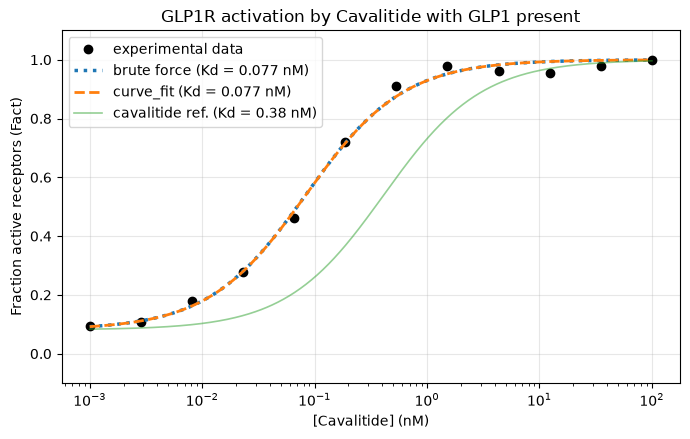

In [ ]:
#Step 1: Import python extensions 
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#Step 2: Define variables
def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

#Step 3: Defining parameters [nM]
Kd1 = 0.17      # L1, GLP1
Kd2_sema = 0.38 # semaglutide (reference)
L1 = 0.015      # GLP1 (fasting)
L2 = np.logspace(-3, 2, 500)

#Step 4: Load in data from csv file
data = np.loadtxt("C:/Users/sarah/BME 2315/Module 3/Module_3/cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

#Step 5: Brute force method
Kd2_candidates = np.logspace(-3, 3, 2000)
SSEs = [np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, k))**2) for k in Kd2_candidates]
i = int(np.argmin(SSEs))
Kd2_brute, SSE_brute = Kd2_candidates[i], SSEs[i]
print(f"Brute-force Kd2 = {Kd2_brute:.4f} nM (SSE = {SSE_brute:.5f})")

#Step 6: Curve fit method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[Kd2_brute], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.4f} +/- {np.sqrt(pcov[0,0]):.4f} nM (SSE = {SSE_fit:.5f})")

#Step 7: Making and printing plots
plt.figure(figsize=(7, 4.5))
plt.semilogx(L2_loaded, Fact_loaded, "ko", label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2.5,
             label=f"brute force (Kd = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curve_fit (Kd = {Kd2_fit:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_sema), "-", lw=1.2, alpha=0.5,
             label=f"cavalitide ref. (Kd = {Kd2_sema} nM)")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cavalitide_fit.png", dpi=150)
plt.show()

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

- To optimize the dosing strategy we lowered the dose from 25mg to 20.8mg and kept the absorption rate, oral bioavailability, and dosing interval the same. This decreases the steady-state blood concentraton closer to 0.5nM. Reducing the dose and keeping everything else the same allows the dosing schedule to stay the same but allowing us to come closer to the concentration we want

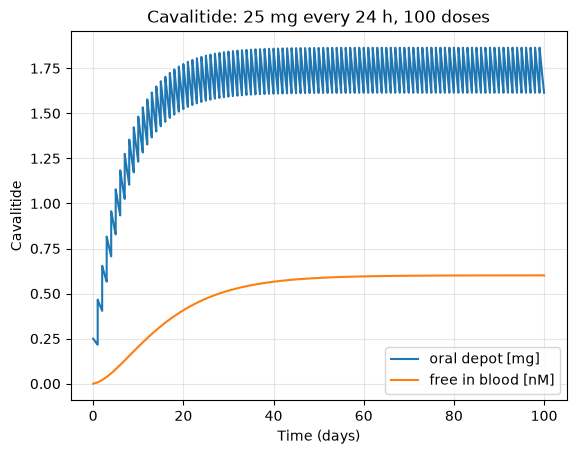

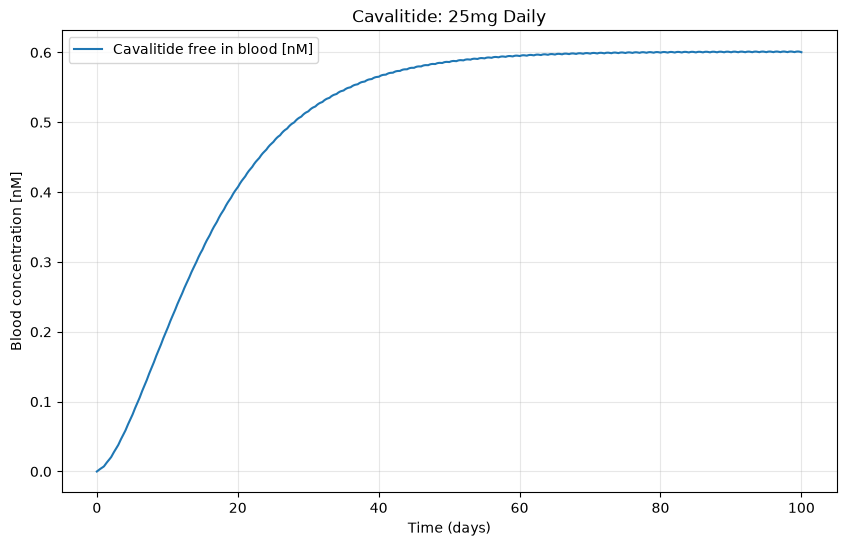

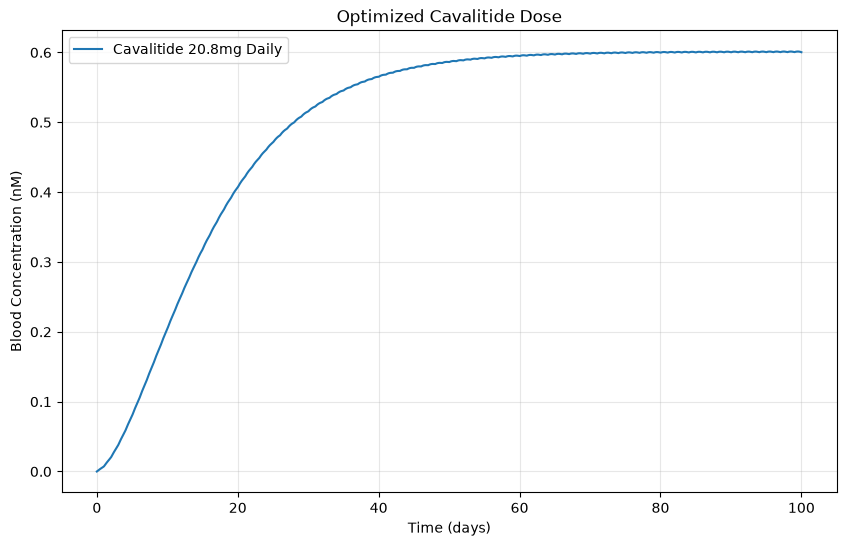

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters

products = {
    'Ozempic': dict(
        Favailable=0.89,
        ka=0.029,
        D=2.0,
        interval=168,
        n_doses=8,
        depot='subcutaneous'
    ),

    'Wegovy': dict(
        Favailable=0.01,
        ka=0.0029,
        D=25,
        interval=24,
        n_doses=100,
        depot='gut (oral)'
    ),

    'Cavalitide': dict(
        Favailable=0.01 , 
        ka=0.006,
        D=25,
        interval=24,
        n_doses=100,
        depot='oral'
    )
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        solution = solve_ivp(
            ODEfunc,
            (t0, t0 + interval),
            y,
            t_eval = t_seg,
            max_step = dt
        )

        y_seg = solution.y
            
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize = (10,6))
plt.plot(t / 24, Ffree*Cc, label="Cavalitide free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Blood concentration [nM]")
plt.title("Cavalitide: 25mg Daily")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize = (10,6))
plt.plot(t / 24, Ffree*Cc, label="Cavalitide 20.8mg Daily")
plt.xlabel("Time (days)")
plt.ylabel("Blood Concentration (nM)")
plt.title("Optimized Cavalitide Dose")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.


Brute-force Kd2 = 0.0767 nM (SSE = 0.00516)
Fitted Kd2 = 0.0770 +/- 0.0045 nM (SSE = 0.00515)


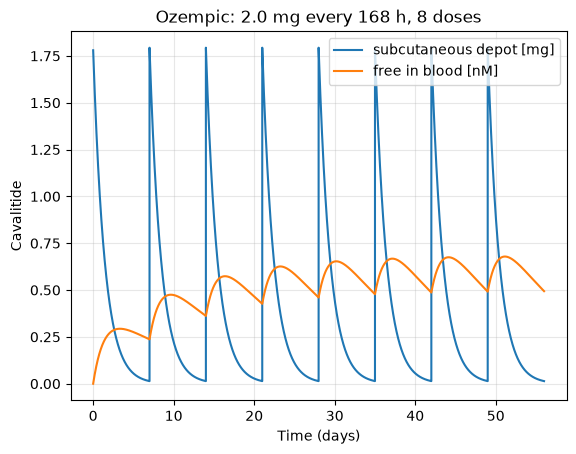

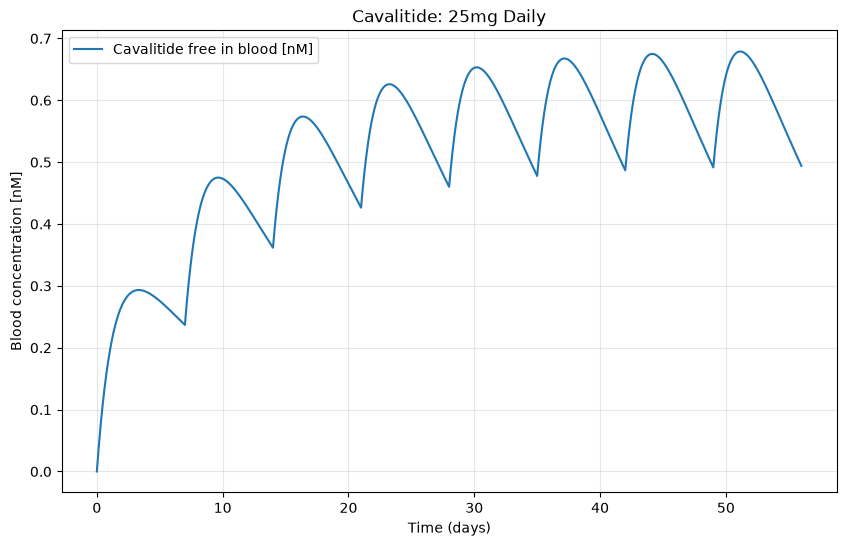

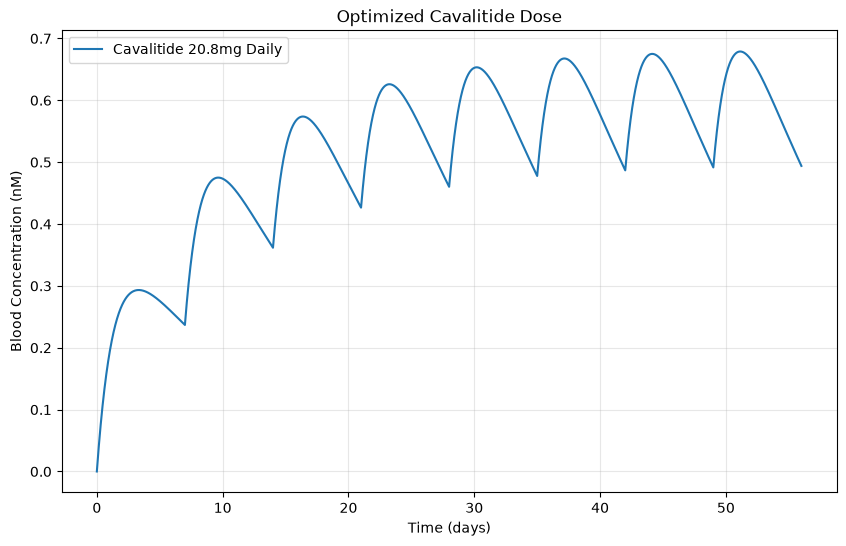

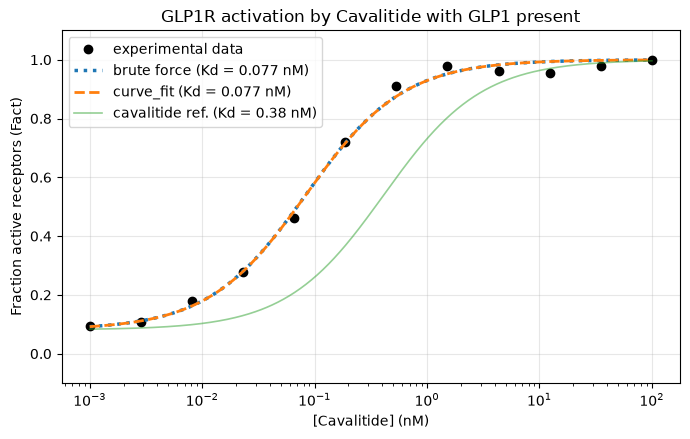

In [ ]:
#Step 1: Import python extensions
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

#Step 2: Define drug variable and parameters
drug = 'Cavalitide'
#drug = 'Wegovy'

products = {
    'Ozempic': dict(
        Favailable=0.89,
        ka=0.029,
        D=2.0,
        interval=168,
        n_doses=8,
        depot='subcutaneous'
    ),


    'Wegovy': dict(
        Favailable=0.01,
        ka=0.0029,
        D=25,
        interval=24,
        n_doses=100,
        depot='gut (oral)'
    ),


    'Cavalitide': dict(
        Favailable=0.01 ,
        ka=0.006,
        D=25,
        interval=24,
        n_doses=100,
        depot='oral'
    )
}

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)


p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin
#in [nM]
Kd1 = 0.17      # L1, GLP1
Kd2_sema = 0.38 # semaglutide (reference)
L1 = 0.015      # GLP1 (fasting)
L2 = np.logspace(-3, 2, 500)

# simulation parameters
dt = 0.1        # h, Euler step size


#Step 3: Defining ODE and simulation functions
def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]


def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
       
        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        solution = solve_ivp(
            ODEfunc,
            (t0, t0 + interval),
            y,
            t_eval = t_seg,
            max_step = dt
        )


        y_seg = solution.y
           
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# Step 3: Load in cavalitide data from csv file
data = np.loadtxt("C:/Users/sarah/BME 2315/Module 3/Module_3/cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]


# Step 4: Brute force method
Kd2_candidates = np.logspace(-3, 3, 2000)
SSEs = [np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, k))**2) for k in Kd2_candidates]
i = int(np.argmin(SSEs))
Kd2_brute, SSE_brute = Kd2_candidates[i], SSEs[i]
print(f"Brute-force Kd2 = {Kd2_brute:.4f} nM (SSE = {SSE_brute:.5f})")


# Step 5: Curve_fit method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[Kd2_brute], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.4f} +/- {np.sqrt(pcov[0,0]):.4f} nM (SSE = {SSE_fit:.5f})")


# Step 6: Run stimulation
t, Asc, Cc = simulate(D, n_doses, interval, dt)


# Step 7: Define and print plots
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize = (10,6))
plt.plot(t / 24, Ffree*Cc, label="Cavalitide free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Blood concentration [nM]")
plt.title("Cavalitide: 25mg Daily")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize = (10,6))
plt.plot(t / 24, Ffree*Cc, label="Cavalitide 20.8mg Daily")
plt.xlabel("Time (days)")
plt.ylabel("Blood Concentration (nM)")
plt.title("Optimized Cavalitide Dose")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4.5))
plt.semilogx(L2_loaded, Fact_loaded, "ko", label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2.5,
             label=f"brute force (Kd = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curve_fit (Kd = {Kd2_fit:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_sema), "-", lw=1.2, alpha=0.5,
             label=f"cavalitide ref. (Kd = {Kd2_sema} nM)")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cavalitide_fit.png", dpi=150)
plt.show()


Prediction: Over the first 100 days of treatment the fraction of active GLP-1 receptors will increase exponentially and then reach a steady state.

Optimization: 

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

There are several limitations in our project, one of which is the amount of experimental data we have in the Cavalitide data set. In task 2 particularly, we assumed the oral bioavailability of Cavalitide because we did not have experimental data. We also made the assumption that the drug has constant absporption and elimination, which may affect the accuracy of our results.

In our future work we would collect and use measured data for absportion and elimination rates, which would increase the accuracy of our results and reduce the possibility of error due to our assumption.

## AI Usage Statement:
We used ChatGPT to check for any bugs in the code, we had trouble generating plots 2 and 3 for task 1 but found the errors and corrected them.

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
Mayo Clinic. (2023, July 22). Obesity. Mayo Clinic. https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*